# 5. E em Varginha?

As três capitais dos notebooks anteriores têm quinze anos de índice mensal. **Varginha (MG) não tem nenhum**: a
cidade não está no FipeZAP, e a API do IBGE não traz o valor do aluguel do Censo 2022 por município.

Este notebook mostra o que dá para fazer nesse caso, que é o da maioria das cidades brasileiras: uma **amostra
pequena de anúncios** para medir o nível atual de preço e aluguel, e a dinâmica (valorização, reajustes)
**emprestada** de cidades que têm série. O resultado é uma estimativa com margem de erro grande, e o texto diz
isso em cada passo.

## A amostra

`dados/manuais/varginha_anuncios.csv` tem os anúncios de **apartamentos** que apareciam, em 3 de outubro de 2026,
na primeira página de venda e na primeira página de aluguel de uma rede de imobiliárias da cidade (a origem de
cada linha está na coluna `fonte`). Só entraram anúncios com área e preço informados.

É uma fotografia de um dia, de uma única fonte, com poucas dezenas de anúncios. Para aumentar a amostra, basta
acrescentar linhas ao arquivo e rodar o notebook de novo.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from comprar_ou_alugar import analise, cenarios, estilo
from comprar_ou_alugar.caminhos import TRATADOS
from comprar_ou_alugar.estilo import br, pct
from comprar_ou_alugar.fontes import varginha
from comprar_ou_alugar.fontes.fipezap import NACIONAL
from comprar_ou_alugar.simulador import Parametros

estilo.aplicar()

anuncios = varginha.ler()  # acrescenta a coluna preco_m2 = preço ÷ área

print(anuncios.groupby("negocio").size().to_string())
anuncios.sort_values("preco_m2").groupby("negocio").head(3)

negocio
aluguel    13
venda      29


,codigo,negocio,bairro,quartos,area_m2,preco,fonte,coletado_em,preco_m2
3,BEF457,aluguel,Centro,3.0,236.0,2000,https://www.redeinovaimoveis.com.br/aluguel/ap...,2026-10-03,8.474576
9,CCR409506,aluguel,Riviera Do Lago,3.0,570.0,7000,https://www.redeinovaimoveis.com.br/aluguel/ap...,2026-10-03,12.280702
8,BEF431,aluguel,Centro,3.0,155.0,1950,https://www.redeinovaimoveis.com.br/aluguel/ap...,2026-10-03,12.580645
38,TL4323,venda,Centro,3.0,550.0,700000,https://www.redeinovaimoveis.com.br/venda/apar...,2026-10-03,1272.727273
30,TL4487,venda,Centro,3.0,158.0,350000,https://www.redeinovaimoveis.com.br/venda/apar...,2026-10-03,2215.189873
25,BEF355,venda,Centro,2.0,108.0,250000,https://www.redeinovaimoveis.com.br/venda/apar...,2026-10-03,2314.814815


## Limpeza

Anúncio é digitado à mão, e a amostra tem erros evidentes de área: um aluguel a mais de R\$ 1.000 por m² e uma
venda a mais de R\$ 45 mil por m² (em São Paulo, a cidade mais cara do índice, o m² custa R\$ 12 mil). A regra
de corte está em `fontes/varginha.py` e é generosa, para tirar só o que é impossível.

In [2]:
print("Faixas aceitas, em R$ por m²:", varginha.FAIXAS_PLAUSIVEIS)
plausivel = varginha.plausivel(anuncios)

print("Anúncios descartados:")
print(
    anuncios.loc[~plausivel, ["codigo", "negocio", "bairro", "area_m2", "preco", "preco_m2"]]
    .round(1)
    .to_string(index=False)
)

amostra = anuncios[plausivel]
venda = amostra.loc[amostra["negocio"] == "venda", "preco_m2"]
aluguel = amostra.loc[amostra["negocio"] == "aluguel", "preco_m2"]
print(f"\nFicaram {len(venda)} anúncios de venda e {len(aluguel)} de aluguel.")

Faixas aceitas, em R$ por m²: {'venda': (1000, 15000), 'aluguel': (8, 60)}
Anúncios descartados:
   codigo negocio          bairro  area_m2  preco  preco_m2
CCR442016 aluguel Sagrado Coração      1.0   1100    1100.0
ELN383190   venda      Vila Pinto     21.0 950000   45238.1

Ficaram 28 anúncios de venda e 12 de aluguel.


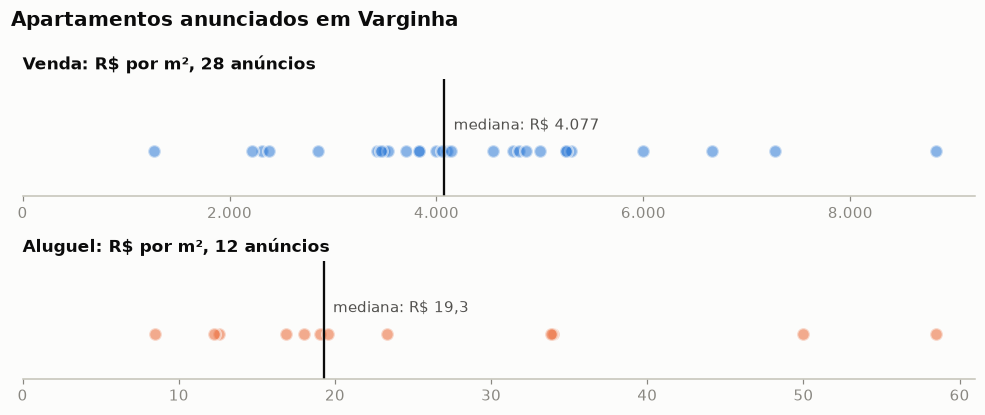

In [3]:
fig, eixos = plt.subplots(2, 1, figsize=(9, 3.8))
for ax, valores, nome, cor in zip(eixos, (venda, aluguel), ("Venda", "Aluguel"), (estilo.AZUL, estilo.LARANJA)):
    ax.scatter(
        valores, np.zeros(len(valores)), s=70, color=cor, alpha=0.55, edgecolors=estilo.SUPERFICIE, linewidths=1.5
    )
    ax.axvline(valores.median(), color=estilo.TINTA, lw=1.5)
    casas = 0 if nome == "Venda" else 1
    ax.annotate(
        f"mediana: R$ {br(valores.median(), casas)}",
        (valores.median(), 0),
        xytext=(6, 14),
        textcoords="offset points",
        fontsize=9.5,
        color=estilo.TINTA_SECUNDARIA,
    )
    ax.set_yticks([])
    ax.set_ylim(-1, 1.6)
    ax.grid(False)
    ax.set_xlim(0)
    estilo.eixo_br(ax.xaxis)
    ax.set_title(f"{nome}: R$ por m², {len(valores)} anúncios", loc="left", fontsize=11, fontweight="bold")
fig.suptitle("Apartamentos anunciados em Varginha", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

Cada ponto é um anúncio. A dispersão é grande, como se espera de uma amostra que mistura bairros e padrões
diferentes, e por isso a medida usada é a **mediana**, que não se abala com valores extremos.

## Quanta confiança dá para ter

Com tão poucos anúncios, a mediana pode mudar bastante se a amostra fosse outra. Para medir essa incerteza, o
*bootstrap* sorteia milhares de amostras do mesmo tamanho a partir da original (com reposição) e recalcula a
mediana em cada uma. O intervalo abaixo contém 90% dos resultados.

In [4]:
sorteio = np.random.default_rng(0)
REPETICOES = 10_000


def medianas_sorteadas(valores: pd.Series) -> np.ndarray:
    return np.median(sorteio.choice(valores.to_numpy(), size=(REPETICOES, len(valores))), axis=1)


venda_sorteada = medianas_sorteadas(venda)
aluguel_sorteado = medianas_sorteadas(aluguel)
rentabilidade_sorteada = analise.anualizar(aluguel_sorteado / venda_sorteada)


def intervalo(valores: np.ndarray) -> tuple[float, float]:
    return tuple(np.quantile(valores, [0.05, 0.95]))


estimativas = {
    "venda (R$/m²)": (venda.median(), intervalo(venda_sorteada), 0),
    "aluguel (R$/m² ao mês)": (aluguel.median(), intervalo(aluguel_sorteado), 1),
}
for nome, (centro, (baixo, alto), casas) in estimativas.items():
    print(f"{nome}: {br(centro, casas)}  (intervalo de 90%: {br(baixo, casas)} a {br(alto, casas)})")

rentabilidade = analise.anualizar(aluguel.median() / venda.median())
rent_baixa, rent_alta = intervalo(rentabilidade_sorteada)
print(
    f"rentabilidade do aluguel: {pct(rentabilidade, 1)} ao ano  (intervalo de 90%: {pct(rent_baixa, 1)} a {pct(rent_alta, 1)})"
)

venda (R$/m²): 4.077  (intervalo de 90%: 3.706 a 4.771)
aluguel (R$/m² ao mês): 19,3  (intervalo de 90%: 16,1 a 33,8)
rentabilidade do aluguel: 5,8% ao ano  (intervalo de 90%: 4,6% a 10,3%)


## Varginha ao lado das capitais

In [5]:
cidades = pd.read_parquet(TRATADOS / "cidades.parquet")
mensal = pd.read_parquet(TRATADOS / "mensal.parquet")

DOADORAS = ["Belo Horizonte", "São Paulo", "Rio de Janeiro", NACIONAL]
series = {cidade: cenarios.serie_da_cidade(cidades, mensal, cidade) for cidade in DOADORAS}

comparacao = {
    "Varginha (amostra)": {
        "venda (R$/m²)": br(venda.median()),
        "aluguel (R$/m² ao mês)": br(aluguel.median(), 1),
        "rentabilidade do aluguel": pct(rentabilidade, 1),
    }
}
for cidade, serie in series.items():
    ultimo = serie.dropna(subset=["venda_preco_m2", "aluguel_preco_m2"]).iloc[-1]
    comparacao[cidade.replace(NACIONAL, "Brasil (índice FipeZAP)")] = {
        "venda (R$/m²)": br(ultimo["venda_preco_m2"]),
        "aluguel (R$/m² ao mês)": br(ultimo["aluguel_preco_m2"], 1),
        "rentabilidade do aluguel": pct(analise.anualizar(ultimo["aluguel_preco_m2"] / ultimo["venda_preco_m2"]), 1),
    }
pd.DataFrame(comparacao).T

,venda (R$/m²),aluguel (R$/m² ao mês),rentabilidade do aluguel
Varginha (amostra),4.077,"19,3","5,8%"
Belo Horizonte,10.667,"50,4","5,8%"
São Paulo,12.143,"65,4","6,7%"
Rio de Janeiro,11.216,"61,4","6,8%"
Brasil (índice FipeZAP),9.957,"54,5","6,8%"


O m² em Varginha custa pouco mais de um terço do das capitais, tanto para comprar quanto para alugar, e a relação
entre os dois (a rentabilidade do aluguel) fica na mesma faixa. Isso é o que importa para a decisão: a conta de
comprar ou alugar depende da **proporção** entre aluguel e preço, não do valor absoluto.

## Comprar ou alugar em Varginha

O apartamento da simulação tem a área mediana da amostra e os preços medianos por m². Os juros são a média
nacional de hoje. Como a cidade não tem história própria, a simulação de Monte Carlo do notebook 4 roda quatro
vezes, cada uma emprestando a dinâmica de um lugar diferente. Nenhuma delas é "a" resposta; juntas, mostram
quanto a conclusão depende dessa escolha.

In [6]:
AREA = float(amostra["area_m2"].median())
juros_hoje = series["Belo Horizonte"]["juros_financiamento_aa"].dropna().iloc[-1]
p = Parametros(valor_imovel=venda.median() * AREA, aluguel_mensal=aluguel.median() * AREA, juros_aa=float(juros_hoje))
print(
    f"Apartamento de {br(AREA)} m²: R$ {br(p.valor_imovel)} para comprar, R$ {br(p.aluguel_mensal)} por mês para alugar."
)

PRAZOS = (5, 10, 20)
linhas = {}
for doadora, serie in series.items():
    vantagem = cenarios.monte_carlo(serie, p, anos=20, caminhos=10_000).vantagem_do_aluguel()
    linhas[f"dinâmica de {doadora.replace(NACIONAL, 'Brasil (índice FipeZAP)')}"] = {
        f"{prazo} anos": pct((vantagem[:, prazo * 12] > 0).mean()) for prazo in PRAZOS
    }
print("Chance de alugar e investir em FIIs ganhar:")
pd.DataFrame(linhas).T

Apartamento de 112 m²: R$ 456.627 para comprar, R$ 2.160 por mês para alugar.


Chance de alugar e investir em FIIs ganhar:


,5 anos,10 anos,20 anos
dinâmica de Belo Horizonte,82%,63%,36%
dinâmica de São Paulo,69%,52%,36%
dinâmica de Rio de Janeiro,78%,69%,56%
dinâmica de Brasil (índice FipeZAP),69%,52%,34%


## E a incerteza da amostra?

A rentabilidade do aluguel é o número que mais pesa, e é justamente o que a amostra mede com menos precisão.
A tabela repete a conta nos dois extremos do intervalo de 90%, com a dinâmica de Belo Horizonte, e mostra também
o retorno real que a carteira precisaria ter para empatar em 20 anos se o imóvel só acompanhar a inflação.

In [7]:
linhas = {}
for nome, taxa in {"extremo baixo": rent_baixa, "estimativa central": rentabilidade, "extremo alto": rent_alta}.items():
    variante = Parametros(
        valor_imovel=p.valor_imovel,
        aluguel_mensal=p.valor_imovel * ((1 + taxa) ** (1 / 12) - 1),
        juros_aa=p.juros_aa,
    )
    vantagem = cenarios.monte_carlo(series["Belo Horizonte"], variante, anos=20, caminhos=10_000).vantagem_do_aluguel()
    coluna = cenarios.sensibilidade(
        variante, anos=20, valorizacao_real_aa=np.array([0.0]), carteira_retorno_real_aa=np.linspace(0, 0.12, 241)
    ).iloc[:, 0]
    linhas[f"{nome} ({pct(taxa, 1)} ao ano)"] = {
        "aluguel mensal": f"R$ {br(variante.aluguel_mensal)}",
        **{f"alugar ganha em {prazo} anos": pct((vantagem[:, prazo * 12] > 0).mean()) for prazo in PRAZOS},
        "retorno real para empatar": pct(coluna[coluna > 0].index.min(), 1),
    }
pd.DataFrame(linhas).T.rename_axis("rentabilidade do aluguel")

,aluguel mensal,alugar ganha em 5 anos,alugar ganha em 10 anos,alugar ganha em 20 anos,retorno real para empatar
rentabilidade do aluguel,,,,,
"extremo baixo (4,6% ao ano)",R$ 1.714,92%,82%,62%,"0,7%"
"estimativa central (5,8% ao ano)",R$ 2.160,82%,63%,36%,"2,5%"
"extremo alto (10,3% ao ano)",R$ 3.731,24%,5%,1%,"10,2%"


## O que dá para dizer

1. **O nível de preços está medido, com margem larga.** O m² de um apartamento em Varginha está na casa dos
   R\$ 4 mil para comprar e dos R\$ 19 para alugar, pouco mais de um terço das capitais. A rentabilidade do
   aluguel fica perto de 5,8% ao ano, mas o intervalo de 90% vai de 4,6% a 10%: com 12 anúncios de aluguel, a
   mediana ainda balança muito.
2. **Na estimativa central, o quadro é um pouco mais favorável ao aluguel do que em São Paulo.** Alugar e
   investir é o resultado mais provável em cinco e em dez anos nas quatro dinâmicas emprestadas. Em vinte anos,
   comprar passa à frente em três delas; só com a dinâmica do Rio (imóveis perdendo para a inflação) o aluguel
   continua na frente.
3. **A incerteza da amostra muda a resposta.** No extremo baixo do intervalo, alugar é barato e ganha na maioria
   dos futuros mesmo em vinte anos; no extremo alto, comprar ganha desde cedo. Com esta amostra, não dá para
   afirmar com segurança de que lado Varginha está.

## O que melhoraria esta análise

- **Mais anúncios, de mais fontes.** Umas cem linhas de cada tipo já estreitariam bastante o intervalo.
- **Comparar iguais com iguais.** A amostra de venda e a de aluguel têm bairros e tamanhos diferentes. Com mais
  dados, dá para calcular a rentabilidade dentro de cada bairro e faixa de tamanho.
- **Repetir a coleta.** Uma fotografia por trimestre, por dois ou três anos, começa a formar a série histórica
  que a cidade não tem.
- **Preço de fechamento.** O ITBI pago à prefeitura registra o valor real das vendas; algumas cidades publicam
  esses dados.